In [1]:
import pandas as pd
from pathlib import Path

# If your notebook is inside the notebooks/ folder
DATA_DIR = Path("../data/raw")

orders = pd.read_csv(DATA_DIR / "orders.csv")

print("Dataset shape:", orders.shape)
print("\nColumn names:")
print(orders.columns.tolist())

print("\nFirst five rows:")
display(orders.head())

print("\nData types:")
print(orders.dtypes)

Dataset shape: (5000, 14)

Column names:
['order_id', 'customer_id', 'restaurant_id', 'order_timestamp', 'item_count', 'order_status', 'order_amount', 'discount', 'delivery_fee', 'tax', 'total_amount', 'hour', 'day_of_week', 'is_weekend']

First five rows:


,order_id,customer_id,restaurant_id,order_timestamp,item_count,order_status,order_amount,discount,delivery_fee,tax,total_amount,hour,day_of_week,is_weekend
0,O000001,C0400,R008,2026-05-25 01:22:00,2,Delivered,474.01,23.70,20,23.70,494.01,1,Monday,False
1,O000002,C0308,R022,2026-05-29 20:41:00,7,Delivered,1476.33,73.82,30,73.82,1506.33,20,Friday,False
2,O000003,C0029,R025,2026-07-08 13:58:00,1,Delivered,154.74,7.74,50,7.74,204.74,13,Wednesday,False
3,O000004,C0144,R002,2026-07-23 19:04:00,1,Delivered,144.95,14.50,40,7.25,177.70,19,Thursday,False
4,O000005,C0076,R009,2026-09-26 09:50:00,7,Delivered,1424.06,71.20,40,71.20,1464.06,9,Saturday,True



Data types:
order_id               str
customer_id            str
restaurant_id          str
order_timestamp        str
item_count           int64
order_status           str
order_amount       float64
discount           float64
delivery_fee         int64
tax                float64
total_amount       float64
hour                 int64
day_of_week            str
is_weekend            bool
dtype: object


In [2]:
# Step 2: Data quality checks

print("Dataset shape:", orders.shape)

print("\nMissing values:")
display(orders.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", orders.duplicated().sum())

print("\nColumn names:")
print(orders.columns.tolist())

Dataset shape: (5000, 14)

Missing values:


order_id           0
customer_id        0
restaurant_id      0
order_timestamp    0
item_count         0
order_status       0
order_amount       0
discount           0
delivery_fee       0
tax                0
total_amount       0
hour               0
day_of_week        0
is_weekend         0
dtype: int64


Duplicate rows: 0

Column names:
['order_id', 'customer_id', 'restaurant_id', 'order_timestamp', 'item_count', 'order_status', 'order_amount', 'discount', 'delivery_fee', 'tax', 'total_amount', 'hour', 'day_of_week', 'is_weekend']


In [4]:
# Convert order_timestamp into datetime format
orders["order_timestamp"] = pd.to_datetime(
    orders["order_timestamp"],
    errors="coerce"
)

# Check invalid timestamps
print("Invalid timestamps:", orders["order_timestamp"].isna().sum())

# Remove rows with missing or invalid timestamps
orders = orders.dropna(subset=["order_timestamp"]).copy()

# Check the date range
print("Start date:", orders["order_timestamp"].min())
print("End date:", orders["order_timestamp"].max())

# Check duplicates
print("Duplicate rows:", orders.duplicated().sum())

display(orders.head())

Invalid timestamps: 0
Start date: 2026-04-01 00:37:00
End date: 2026-09-30 23:43:00
Duplicate rows: 0


,order_id,customer_id,restaurant_id,order_timestamp,item_count,order_status,order_amount,discount,delivery_fee,tax,total_amount,hour,day_of_week,is_weekend
0,O000001,C0400,R008,2026-05-25 01:22:00,2,Delivered,474.01,23.70,20,23.70,494.01,1,Monday,False
1,O000002,C0308,R022,2026-05-29 20:41:00,7,Delivered,1476.33,73.82,30,73.82,1506.33,20,Friday,False
2,O000003,C0029,R025,2026-07-08 13:58:00,1,Delivered,154.74,7.74,50,7.74,204.74,13,Wednesday,False
3,O000004,C0144,R002,2026-07-23 19:04:00,1,Delivered,144.95,14.50,40,7.25,177.70,19,Thursday,False
4,O000005,C0076,R009,2026-09-26 09:50:00,7,Delivered,1424.06,71.20,40,71.20,1464.06,9,Saturday,True


In [5]:
# Count orders for each hour
hourly_demand = (
    orders
    .set_index("order_timestamp")
    .resample("h")
    .size()
    .reset_index(name="order_count")
)

print("Hourly dataset shape:", hourly_demand.shape)

display(hourly_demand.head(10))

Hourly dataset shape: (4392, 2)


,order_timestamp,order_count
0,2026-04-01 00:00:00,1
1,2026-04-01 01:00:00,1
2,2026-04-01 02:00:00,2
3,2026-04-01 03:00:00,2
4,2026-04-01 04:00:00,1
5,2026-04-01 05:00:00,2
6,2026-04-01 06:00:00,3
7,2026-04-01 07:00:00,1
8,2026-04-01 08:00:00,1
9,2026-04-01 09:00:00,1


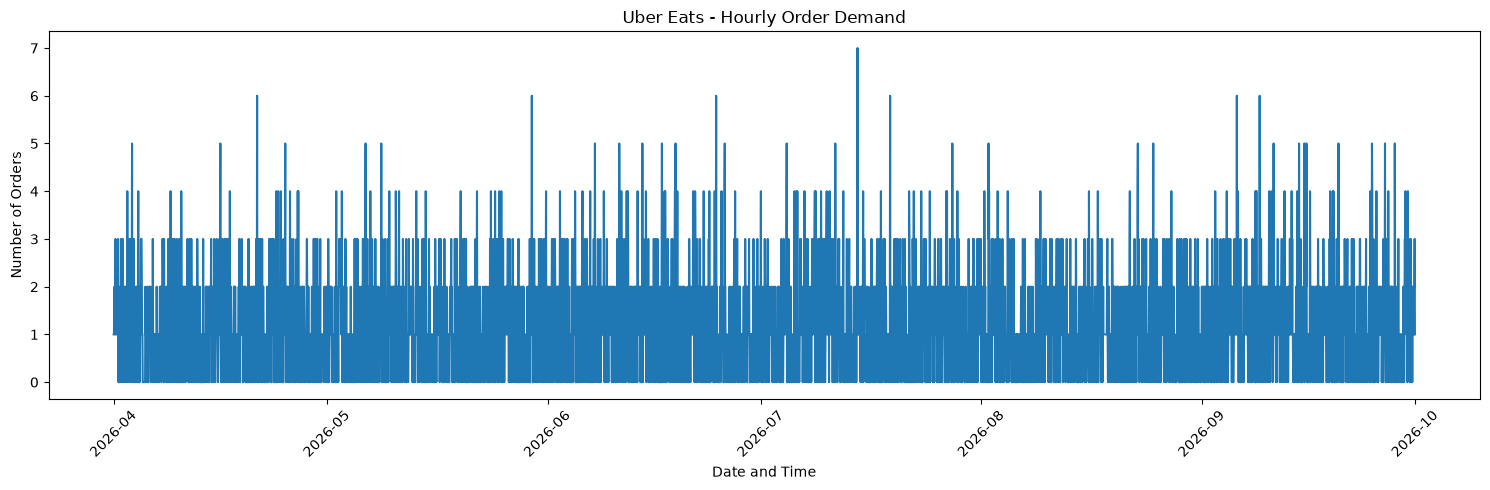

In [6]:
import matplotlib.pyplot as plt

# Plot hourly order demand over time
plt.figure(figsize=(15, 5))

plt.plot(
    hourly_demand["order_timestamp"],
    hourly_demand["order_count"]
)

plt.title("Uber Eats - Hourly Order Demand")
plt.xlabel("Date and Time")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

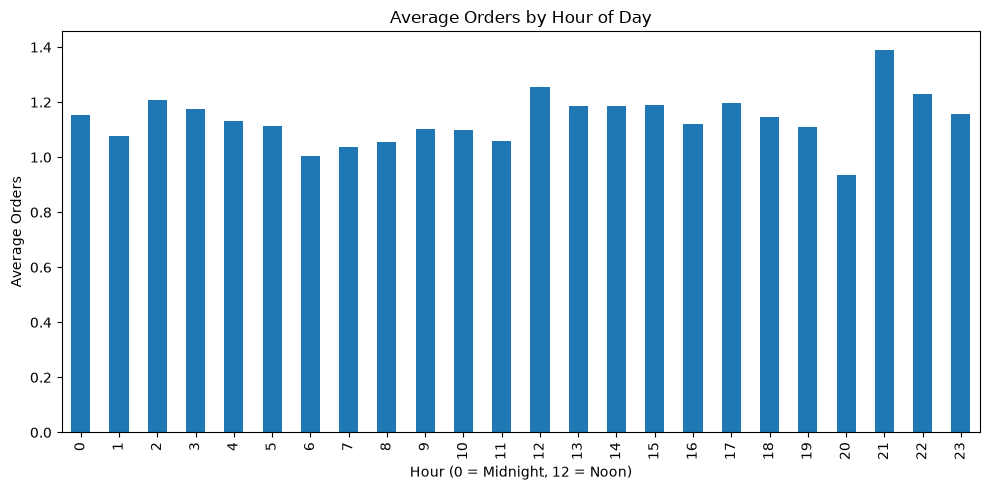

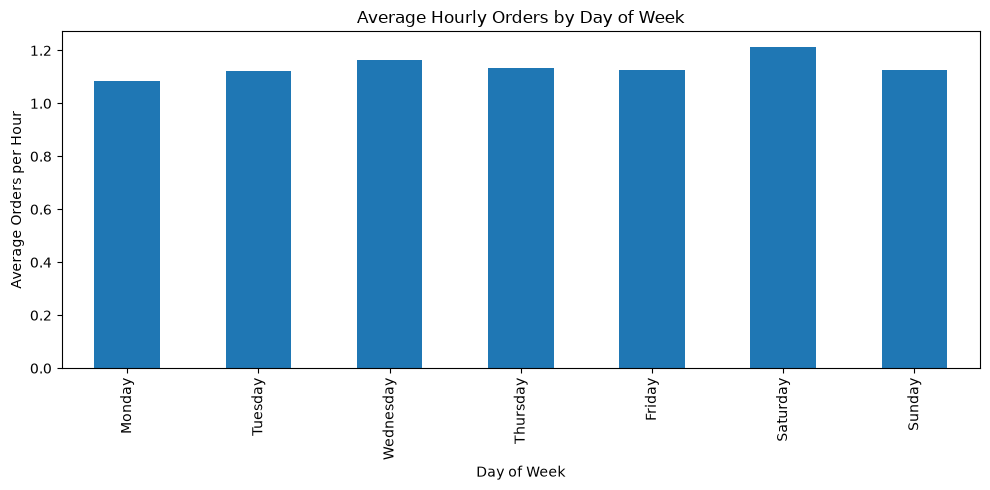

In [7]:
hourly_demand["hour"] = hourly_demand["order_timestamp"].dt.hour
hourly_demand["day_of_week"] = hourly_demand["order_timestamp"].dt.day_name()
hourly_demand["date"] = hourly_demand["order_timestamp"].dt.date

# Average orders for each hour of the day
hourly_pattern = (
    hourly_demand.groupby("hour")["order_count"]
    .mean()
)

plt.figure(figsize=(10, 5))
hourly_pattern.plot(kind="bar")
plt.title("Average Orders by Hour of Day")
plt.xlabel("Hour (0 = Midnight, 12 = Noon)")
plt.ylabel("Average Orders")
plt.tight_layout()
plt.show()

# Average orders by day of week
daily_pattern = (
    hourly_demand.groupby("day_of_week")["order_count"]
    .mean()
    .reindex([
        "Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"
    ])
)

plt.figure(figsize=(10, 5))
daily_pattern.plot(kind="bar")
plt.title("Average Hourly Orders by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Orders per Hour")
plt.tight_layout()
plt.show()

In [8]:
print("First timestamp:", hourly_demand["order_timestamp"].min())
print("Last timestamp:", hourly_demand["order_timestamp"].max())
print("Total hourly records:", len(hourly_demand))

print(
    "Missing hourly timestamps:",
    hourly_demand["order_timestamp"].diff().dropna().ne(
        pd.Timedelta(hours=1)
    ).sum()
)

print("Average orders per hour:", round(hourly_demand["order_count"].mean(), 2))
print("Maximum orders in an hour:", hourly_demand["order_count"].max())
print("Minimum orders in an hour:", hourly_demand["order_count"].min())

First timestamp: 2026-04-01 00:00:00
Last timestamp: 2026-09-30 23:00:00
Total hourly records: 4392
Missing hourly timestamps: 0
Average orders per hour: 1.14
Maximum orders in an hour: 7
Minimum orders in an hour: 0


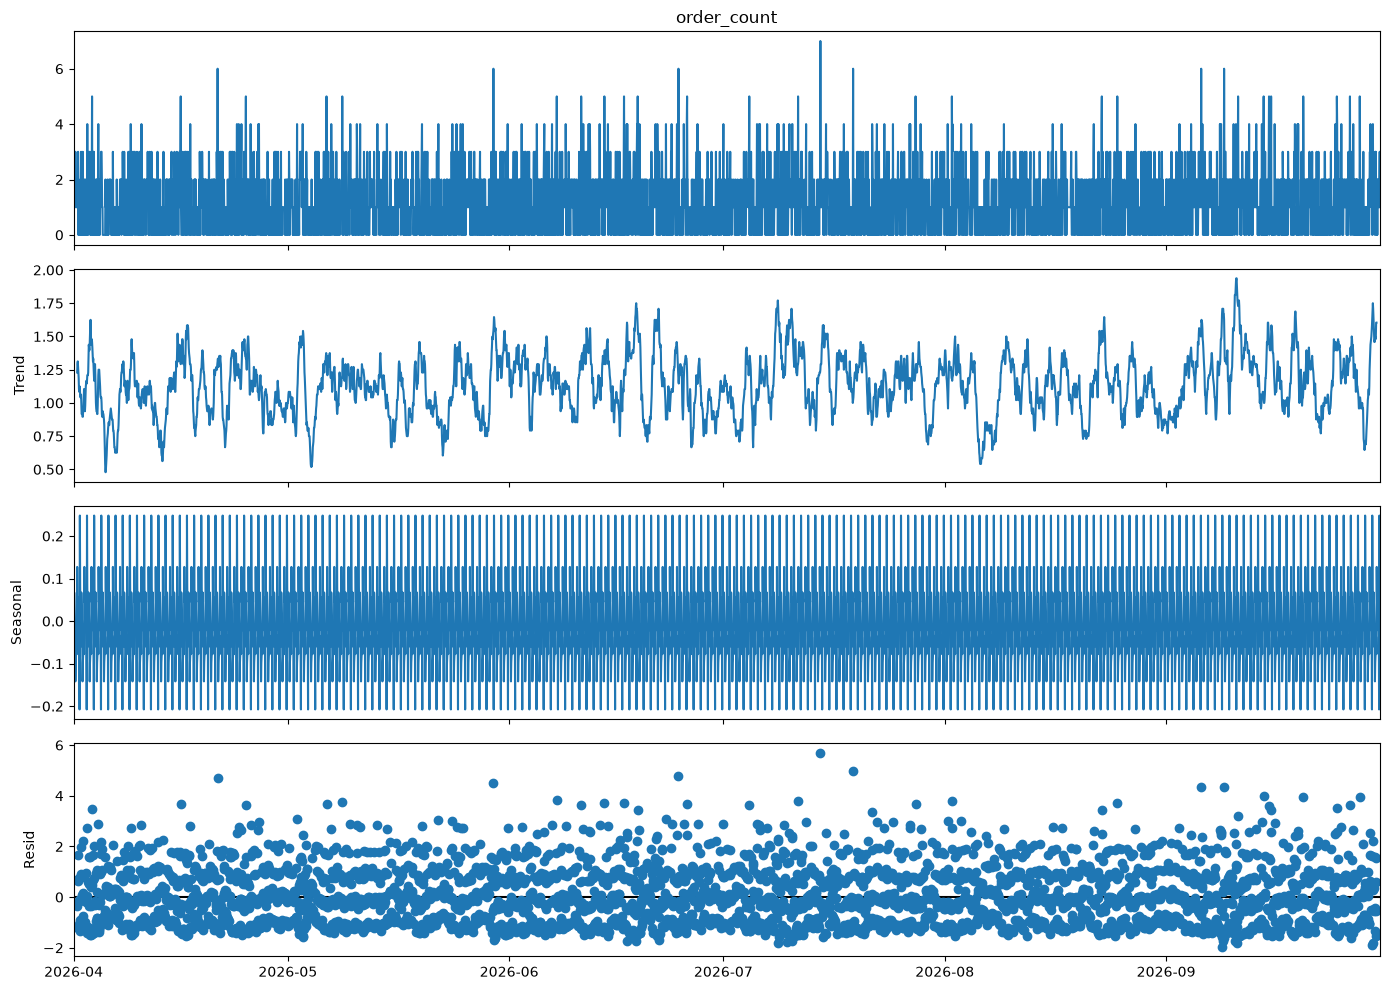

In [10]:
# Step 8: Time-series decomposition

import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Prepare hourly demand as a time series
demand_series = (
    hourly_demand
    .set_index("order_timestamp")["order_count"]
    .asfreq("h")
)

# Decompose demand using a 24-hour seasonal period
decomposition = seasonal_decompose(
    demand_series,
    model="additive",
    period=24
)

# Plot the components
fig = decomposition.plot()
fig.set_size_inches(14, 10)
plt.tight_layout()
plt.show()

In [11]:
# Step 9: ADF stationarity test

from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(demand_series.dropna())

print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 4))
print("Critical Value (1%):", round(adf_result[4]["1%"], 4))
print("Critical Value (5%):", round(adf_result[4]["5%"], 4))
print("Critical Value (10%):", round(adf_result[4]["10%"], 4))

if adf_result[1] < 0.05:
    print("\nConclusion: Reject the unit-root null hypothesis.")
    print("The series appears stationary under this test.")
else:
    print("\nConclusion: Fail to reject the unit-root null hypothesis.")
    print("The series may be non-stationary.")

ADF Statistic: -34.3815
p-value: 0.0
Critical Value (1%): -3.4318
Critical Value (5%): -2.8622
Critical Value (10%): -2.5671

Conclusion: Reject the unit-root null hypothesis.
The series appears stationary under this test.


/tmp/ipykernel_24608/2589020574.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(demand_series.dropna())


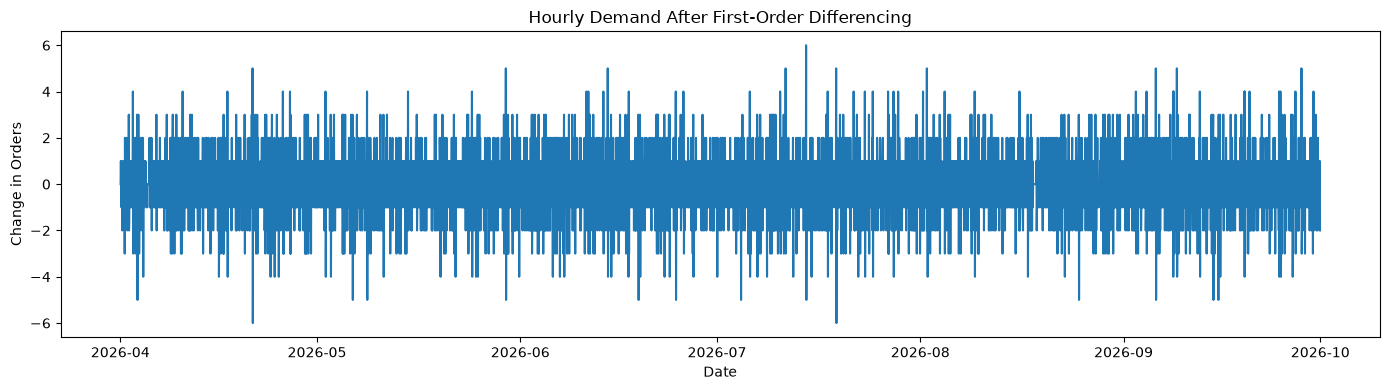

ADF Statistic after differencing: -20.3287
p-value after differencing: 0.0
The differenced series appears stationary under the ADF test.


/tmp/ipykernel_24608/6145551.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  diff_adf = adfuller(demand_diff)


In [12]:
# Step 10: First-order differencing

demand_diff = demand_series.diff().dropna()

plt.figure(figsize=(14, 4))
plt.plot(demand_diff)
plt.title("Hourly Demand After First-Order Differencing")
plt.xlabel("Date")
plt.ylabel("Change in Orders")
plt.tight_layout()
plt.show()

# ADF test on differenced data
diff_adf = adfuller(demand_diff)

print("ADF Statistic after differencing:", round(diff_adf[0], 4))
print("p-value after differencing:", round(diff_adf[1], 4))

if diff_adf[1] < 0.05:
    print("The differenced series appears stationary under the ADF test.")
else:
    print("The differenced series may still be non-stationary.")

In [13]:
# Step 11: Chronological train/test split

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure continuous hourly frequency
demand_series = demand_series.asfreq("h")

split_index = int(len(demand_series) * 0.80)

train = demand_series.iloc[:split_index]
test = demand_series.iloc[split_index:]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training ends:", train.index.max())
print("Testing starts:", test.index.min())

Training observations: 3513
Testing observations: 879
Training ends: 2026-08-25 08:00:00
Testing starts: 2026-08-25 09:00:00


In [14]:
# Step 12: Fit ARIMA(1, 0, 1)

arima_model = ARIMA(
    train,
    order=(1, 0, 1)
)

arima_fit = arima_model.fit()

# Forecast the test period
arima_forecast = arima_fit.forecast(steps=len(test))

# Keep predictions non-negative for order demand
arima_forecast = arima_forecast.clip(lower=0)

print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:            order_count   No. Observations:                 3513
Model:                 ARIMA(1, 0, 1)   Log Likelihood               -5250.574
Date:                Thu, 29 Oct 2026   AIC                          10509.148
Time:                        12:29:42   BIC                          10533.805
Sample:                    04-01-2026   HQIC                         10517.946
                         - 08-25-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.1249      0.023     49.833      0.000       1.081       1.169
ar.L1         -0.0554      0.627     -0.088      0.930      -1.284       1.173
ma.L1          0.0829      0.626      0.133      0.8

In [15]:
# Step 13: Evaluate forecast accuracy

mae = mean_absolute_error(test, arima_forecast)

rmse = np.sqrt(mean_squared_error(test, arima_forecast))

# MAPE is unstable when actual demand is zero.
# Calculate it only for hours with positive actual demand.
positive_mask = test > 0

if positive_mask.any():
    mape = (
        np.abs(
            (test[positive_mask] - arima_forecast[positive_mask])
            / test[positive_mask]
        ).mean() * 100
    )
else:
    mape = np.nan

print("ARIMA MAE:", round(mae, 3))
print("ARIMA RMSE:", round(rmse, 3))
print("ARIMA MAPE on positive-demand hours:", round(mape, 2), "%")

ARIMA MAE: 0.86
ARIMA RMSE: 1.122
ARIMA MAPE on positive-demand hours: 31.71 %


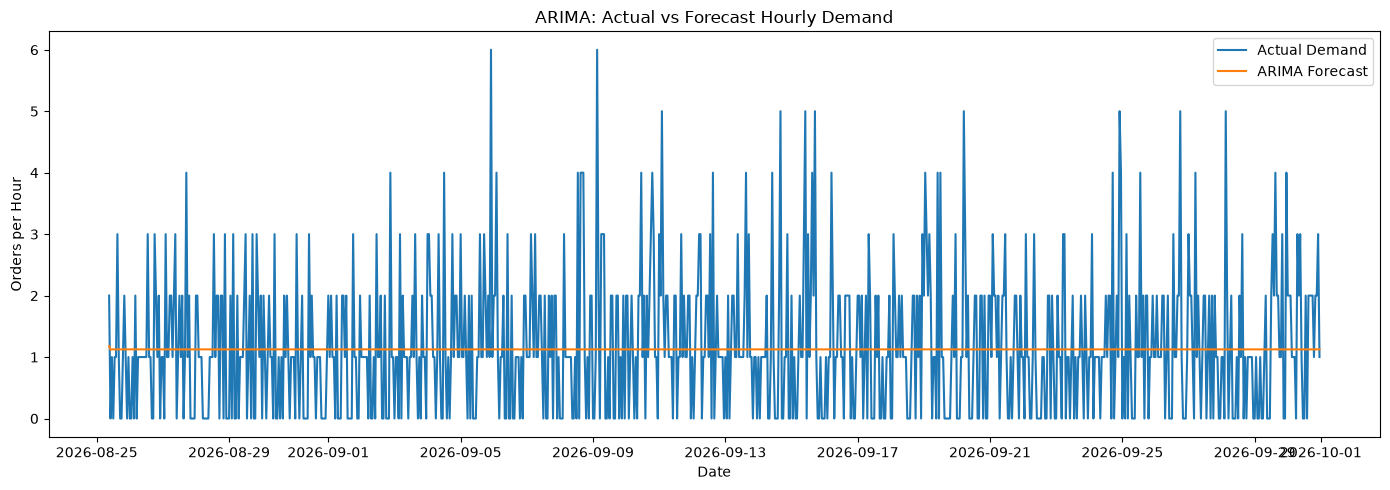

In [16]:
plt.figure(figsize=(14, 5))

plt.plot(test.index, test.values, label="Actual Demand")
plt.plot(
    test.index,
    arima_forecast.values,
    label="ARIMA Forecast"
)

plt.title("ARIMA: Actual vs Forecast Hourly Demand")
plt.xlabel("Date")
plt.ylabel("Orders per Hour")
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
# Step 14: Prepare data for Prophet

from prophet import Prophet
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Prophet requires columns named ds and y
prophet_train = train.rename_axis("ds").reset_index()
prophet_train.columns = ["ds", "y"]

prophet_test = test.rename_axis("ds").reset_index()
prophet_test.columns = ["ds", "y"]

print(prophet_train.head())

                   ds  y
0 2026-04-01 00:00:00  1
1 2026-04-01 01:00:00  1
2 2026-04-01 02:00:00  2
3 2026-04-01 03:00:00  2
4 2026-04-01 04:00:00  1


In [20]:
# Step 15: Fit Prophet

prophet_model = Prophet(
    daily_seasonality=True,
    weekly_seasonality=True,
    yearly_seasonality=False
)

prophet_model.fit(prophet_train)

# Forecast the same test period
future = prophet_test[["ds"]].copy()

prophet_predictions = prophet_model.predict(future)

prophet_forecast = pd.Series(
    np.maximum(prophet_predictions["yhat"].to_numpy(), 0),
    index=test.index
)

print(prophet_predictions[["ds", "yhat", "yhat_lower", "yhat_upper"]].head())

12:34:54 - cmdstanpy - INFO - Chain [1] start processing
12:34:54 - cmdstanpy - INFO - Chain [1] done processing


                   ds      yhat  yhat_lower  yhat_upper
0 2026-08-25 09:00:00  1.111851   -0.285845    2.439913
1 2026-08-25 10:00:00  1.158744   -0.151101    2.534606
2 2026-08-25 11:00:00  1.179687   -0.161086    2.660838
3 2026-08-25 12:00:00  1.191146   -0.208981    2.575847
4 2026-08-25 13:00:00  1.211360   -0.172304    2.585337


In [21]:
# Step 16: Evaluate Prophet

prophet_mae = mean_absolute_error(test, prophet_forecast)

prophet_rmse = np.sqrt(
    mean_squared_error(test, prophet_forecast)
)

positive_mask = test > 0

prophet_mape = (
    np.abs(
        (test[positive_mask] - prophet_forecast[positive_mask])
        / test[positive_mask]
    ).mean() * 100
    if positive_mask.any()
    else np.nan
)

print("Prophet MAE:", round(prophet_mae, 3))
print("Prophet RMSE:", round(prophet_rmse, 3))
print("Prophet MAPE on positive-demand hours:", round(prophet_mape, 2), "%")

Prophet MAE: 0.866
Prophet RMSE: 1.124
Prophet MAPE on positive-demand hours: 32.13 %


In [22]:
# Step 17: Compare models

comparison = pd.DataFrame({
    "Model": ["ARIMA(1,0,1)", "Prophet"],
    "MAE": [mae, prophet_mae],
    "RMSE": [rmse, prophet_rmse],
    "MAPE_positive_hours": [mape, prophet_mape]
})

display(comparison.round(3))

,Model,MAE,RMSE,MAPE_positive_hours
0,"ARIMA(1,0,1)",0.860,1.122,31.712
1,Prophet,0.866,1.124,32.126


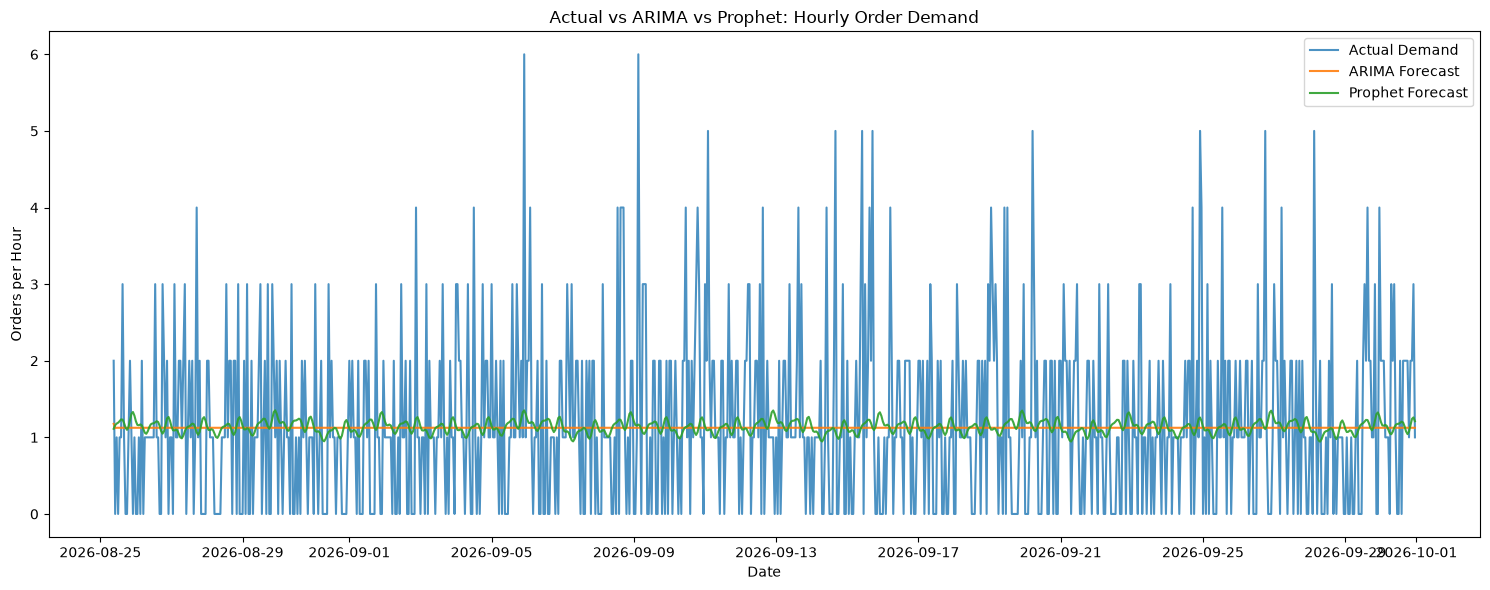

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    test.index,
    test.values,
    label="Actual Demand",
    alpha=0.8
)

plt.plot(
    test.index,
    arima_forecast.values,
    label="ARIMA Forecast",
    alpha=0.9
)

plt.plot(
    test.index,
    prophet_forecast.values,
    label="Prophet Forecast",
    alpha=0.9
)

plt.title("Actual vs ARIMA vs Prophet: Hourly Order Demand")
plt.xlabel("Date")
plt.ylabel("Orders per Hour")
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
# Predict each test hour using the same hour from the previous week

baseline_forecast = demand_series.shift(168).loc[test.index]

# Remove any missing baseline predictions, if present
valid = baseline_forecast.notna()

baseline_actual = test.loc[valid]
baseline_pred = baseline_forecast.loc[valid]

baseline_mae = mean_absolute_error(
    baseline_actual,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(baseline_actual, baseline_pred)
)

positive_mask = baseline_actual > 0

baseline_mape = (
    np.abs(
        (baseline_actual[positive_mask] -
         baseline_pred[positive_mask]) /
        baseline_actual[positive_mask]
    ).mean() * 100
    if positive_mask.any()
    else np.nan
)

print("Seasonal-naive MAE:", round(baseline_mae, 3))
print("Seasonal-naive RMSE:", round(baseline_rmse, 3))
print("Seasonal-naive MAPE:", round(baseline_mape, 2), "%")

Seasonal-naive MAE: 1.231
Seasonal-naive RMSE: 1.614
Seasonal-naive MAPE: 72.0 %


In [25]:
# Compare all models on the same test observations

comparison_all = pd.DataFrame({
    "Model": [
        "ARIMA(1,0,1)",
        "Prophet",
        "Seasonal Naive (168 hours)"
    ],
    "MAE": [
        mae,
        prophet_mae,
        baseline_mae
    ],
    "RMSE": [
        rmse,
        prophet_rmse,
        baseline_rmse
    ],
    "MAPE_positive_hours": [
        mape,
        prophet_mape,
        baseline_mape
    ]
})

display(comparison_all.round(3))

,Model,MAE,RMSE,MAPE_positive_hours
0,"ARIMA(1,0,1)",0.860,1.122,31.712
1,Prophet,0.866,1.124,32.126
2,Seasonal Naive (168 hours),1.231,1.614,71.998
